# Notebook 5 -- SSI + SINDy + Filtre de Kalman etendu : pipeline complet et comparaison aux baselines
### Un observateur d'etat peut-il compenser une dynamique non identifiee ?

> ****Note de provenance.**** Les notebooks de recherche originaux seront présents dans le répertoire du projet, accompagnés des données et des fichiers nécessaires aux expériences. Le présent notebook fait uniquement office de **notebook d'analyse et de synthèse** : il ne remplace pas les notebooks originaux et ne constitue pas une nouvelle implémentation des expérimentations.
>
> Le code, les résultats et les sorties présentés dans ce notebook sont analysés à partir des travaux réalisés dans les notebooks originaux. Aucun résultat n'a été recalculé ni inventé : lorsqu'une information n'était pas déterminable à partir des notebooks ou des données disponibles, cela est signalé explicitement plutôt que comblé. Ce notebook n'est donc pas conçu pour être exécuté isolément de haut en bas ; il a pour objectif de **documenter, structurer, comparer et interpréter les résultats déjà obtenus**, ainsi que de mettre en évidence la progression scientifique entre les différentes approches étudiées.


## Objectif

Construire et evaluer, de bout en bout, le pipeline complet **SSI -> SINDy -> Filtre de Kalman
etendu (EKF)**, et le comparer explicitement a quatre baselines (interpolation, regression
lineaire, PCA, SSI+Kalman *sans* SINDy) sur des scenarios de panne realistes (points isoles,
fenetre continue, region de pics, fenetre longue). L'objectif est de repondre a une question
laissee ouverte par le notebook 4 : **un observateur d'etat, recalant continuellement son
estimation a partir des mesures disponibles, peut-il compenser une dynamique SINDy degeneree
(nulle ou instable) ?**

## Motivation

Le notebook 4 a etabli que SINDy ne parvient pas a identifier une dynamique utilisable de l'etat
latent SSI. Plutot que d'abandonner l'idee d'un modele d'etat, l'idee testee ici est d'introduire
un **observateur** (filtre de Kalman etendu) qui ne repose pas uniquement sur la dynamique predite :
il combine cette prediction (aussi imparfaite soit-elle) avec les mesures reellement disponibles a
chaque instant, ponderees par leur fiabilite estimee. Meme avec une dynamique degeneree, l'EKF
pourrait en principe rester utile grace a cette correction continue par les mesures -- c'est cette
hypothese que ce notebook met a l'epreuve.

## Hypothese

Un filtre de Kalman etendu, utilisant la dynamique SINDy (aussi imparfaite soit-elle) comme modele
de prediction et les capteurs disponibles comme mesures de correction, permet d'estimer l'etat
latent -- et donc de reconstruire le capteur manquant -- de facon plus fiable qu'une simple
relation statique (notebook 2), y compris pendant une fenetre de panne prolongee.

## Methodologie

**Identification en sous-espace stochastique (SSI-COV).** Un modele d'etat lineaire discret
x_(k+1) = A.x_k + w_k, y_k = C.x_k + v_k est identifie par l'algorithme classique de l'analyse
modale operationnelle (Peeters & De Roeck, 1999), a partir de la sequence de covariance des
sorties. L'ordre du modele (dimension de l'etat latent) est choisi par Validation en minimisant
l'erreur de reconstruction one-step-ahead.

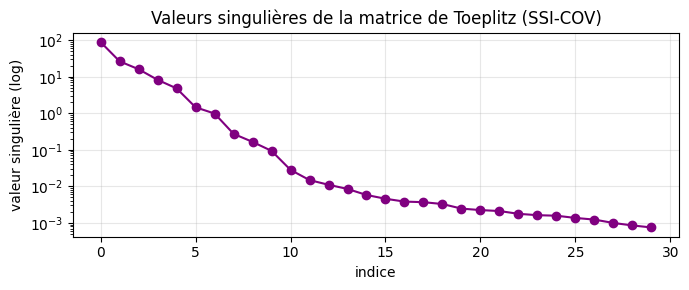

In [21]:
def ssi_cov(Y, s, order):
    '''SSI covariance-driven. Y: (N, m). Retourne A (n,n), C (m,n), valeurs singulières.'''
    N, m = Y.shape
    Yc = Y - Y.mean(axis=0, keepdims=True)
    max_lag = 2 * s
    R = np.zeros((max_lag, m, m))
    for i in range(max_lag):
        R[i] = (Yc[i:].T @ Yc[:N - i]) / (N - i)
    T = np.zeros((s * m, s * m))
    for i in range(s):
        for j in range(s):
            lag = i + j + 1
            T[i*m:(i+1)*m, j*m:(j+1)*m] = R[min(lag, max_lag - 1)]
    U, Sv, Vt = np.linalg.svd(T)
    U1 = U[:, :order]
    S1 = Sv[:order]
    O = U1 @ np.diag(np.sqrt(np.maximum(S1, 1e-12)))
    C = O[:m, :]
    A = np.linalg.pinv(O[:-m, :]) @ O[m:, :]
    return A, C, Sv


def ssi_observability(C, A, s):
    order = A.shape[0]
    blocks = [C]
    Ak = np.eye(order)
    for _ in range(1, s):
        Ak = Ak @ A
        blocks.append(C @ Ak)
    return np.vstack(blocks)


def ssi_estimate_states(Y, C, A, s):
    '''Estime la séquence d'état latent par projection sur la matrice d'observabilité.'''
    N, m = Y.shape
    O = ssi_observability(C, A, s)
    O_pinv = np.linalg.pinv(O)
    n_out = N - s + 1
    X = np.zeros((n_out, A.shape[0]))
    for k in range(n_out):
        X[k] = O_pinv @ Y[k:k+s].reshape(-1)
    return X

Y_train_full = train_s[ALL_SSI_SENSORS].values   # cible incluse en Train (pour connaître C_missing)

# --- Valeurs singulières pour aider au choix de l'ordre ---
_, _, Sv_full = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, max(SSI_ORDER_CANDIDATES))
fig, ax = plt.subplots(figsize=(7,3))
ax.semilogy(Sv_full[:30], "o-", color="purple")
ax.set_xlabel("indice")
ax.set_ylabel("valeur singulière (log)")
ax.set_title("Valeurs singulières de la matrice de Toeplitz (SSI-COV)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:
# --- Sélection de l'ordre du modèle sur Validation : erreur de reconstruction one-step-ahead ---
def one_step_ahead_error(A, C, s, Y):
    X = ssi_estimate_states(Y, C, A, s)
    Ypred = X[:-1] @ (C @ A).T   # y_{k+1} approx C A x_k  (à un décalage près de la fenêtre s)
    Ytrue_shift = Y[s: s + Ypred.shape[0]]
    n_cmp = min(len(Ypred), len(Ytrue_shift))
    return np.sqrt(np.mean((Ypred[:n_cmp] - Ytrue_shift[:n_cmp])**2))

val_errors = {}
Y_val_full = val_s[ALL_SSI_SENSORS].values
for order in SSI_ORDER_CANDIDATES:
    try:
        A_o, C_o, _ = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, order)
        err = one_step_ahead_error(A_o, C_o, SSI_BLOCK_ROWS, Y_val_full)
        val_errors[order] = err
    except Exception as e:
        val_errors[order] = np.inf
        print(f"Ordre {order} : échec ({e})")

print("Erreur de reconstruction one-step-ahead (Validation) par ordre :")
for o, e in val_errors.items():
    print(f"  ordre={o:2d}  RMSE_val={e:.4f}")

SSI_ORDER = min(val_errors, key=val_errors.get)
print(f"\n>>> Ordre retenu (minimise l'erreur de Validation) : n = {SSI_ORDER}")

A, C_ssi, Sv = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, SSI_ORDER)
print("\nMatrice A (dynamique discrète latente) :")
print(np.round(A, 4))
print("\nMatrice C (capteurs = fonction de l'état latent), lignes = [cible] + capteurs dispo :")
print(pd.DataFrame(np.round(C_ssi, 3), index=ALL_SSI_SENSORS, columns=[f"x{i+1}" for i in range(SSI_ORDER)]))

C_target_row = C_ssi[0:1, :]                 # ligne correspondant au capteur cible
C_obs_full   = C_ssi[1:, :]                   # lignes correspondant aux capteurs disponibles (ordre = selected_sensors)


Erreur de reconstruction one-step-ahead (Validation) par ordre :
  ordre= 2  RMSE_val=0.4972
  ordre= 3  RMSE_val=0.3694
  ordre= 4  RMSE_val=0.3615
  ordre= 5  RMSE_val=0.1754
  ordre= 6  RMSE_val=0.1135
  ordre= 8  RMSE_val=0.0851

>>> Ordre retenu (minimise l'erreur de Validation) : n = 8

Matrice A (dynamique discrète latente) :
[[ 9.994e-01 -2.000e-04 -1.000e-04  2.000e-04  1.000e-04 -3.000e-04
  -6.000e-04  1.000e-04]
 [-6.000e-04  9.994e-01  0.000e+00 -7.000e-04  7.000e-04 -2.000e-04
  -1.000e-04 -2.000e-04]
 [ 3.000e-04  6.000e-04  9.990e-01  6.000e-04 -7.000e-04 -1.000e-04
  -4.000e-04 -6.000e-04]
 [-6.000e-04 -4.000e-04 -3.000e-04  9.974e-01  4.000e-04  5.000e-04
  -1.300e-03 -0.000e+00]
 [ 6.000e-04 -0.000e+00  4.000e-04 -9.000e-04  9.985e-01  1.400e-03
   1.500e-03 -4.000e-04]
 [-3.000e-04 -2.000e-04 -6.000e-04  3.000e-04 -9.000e-04  9.919e-01
   2.300e-03  4.000e-03]
 [ 8.000e-04  1.100e-03 -7.000e-04  1.500e-03  3.000e-04 -1.100e-03
   9.968e-01  9.000e-04]
 [ 6.000e-04  

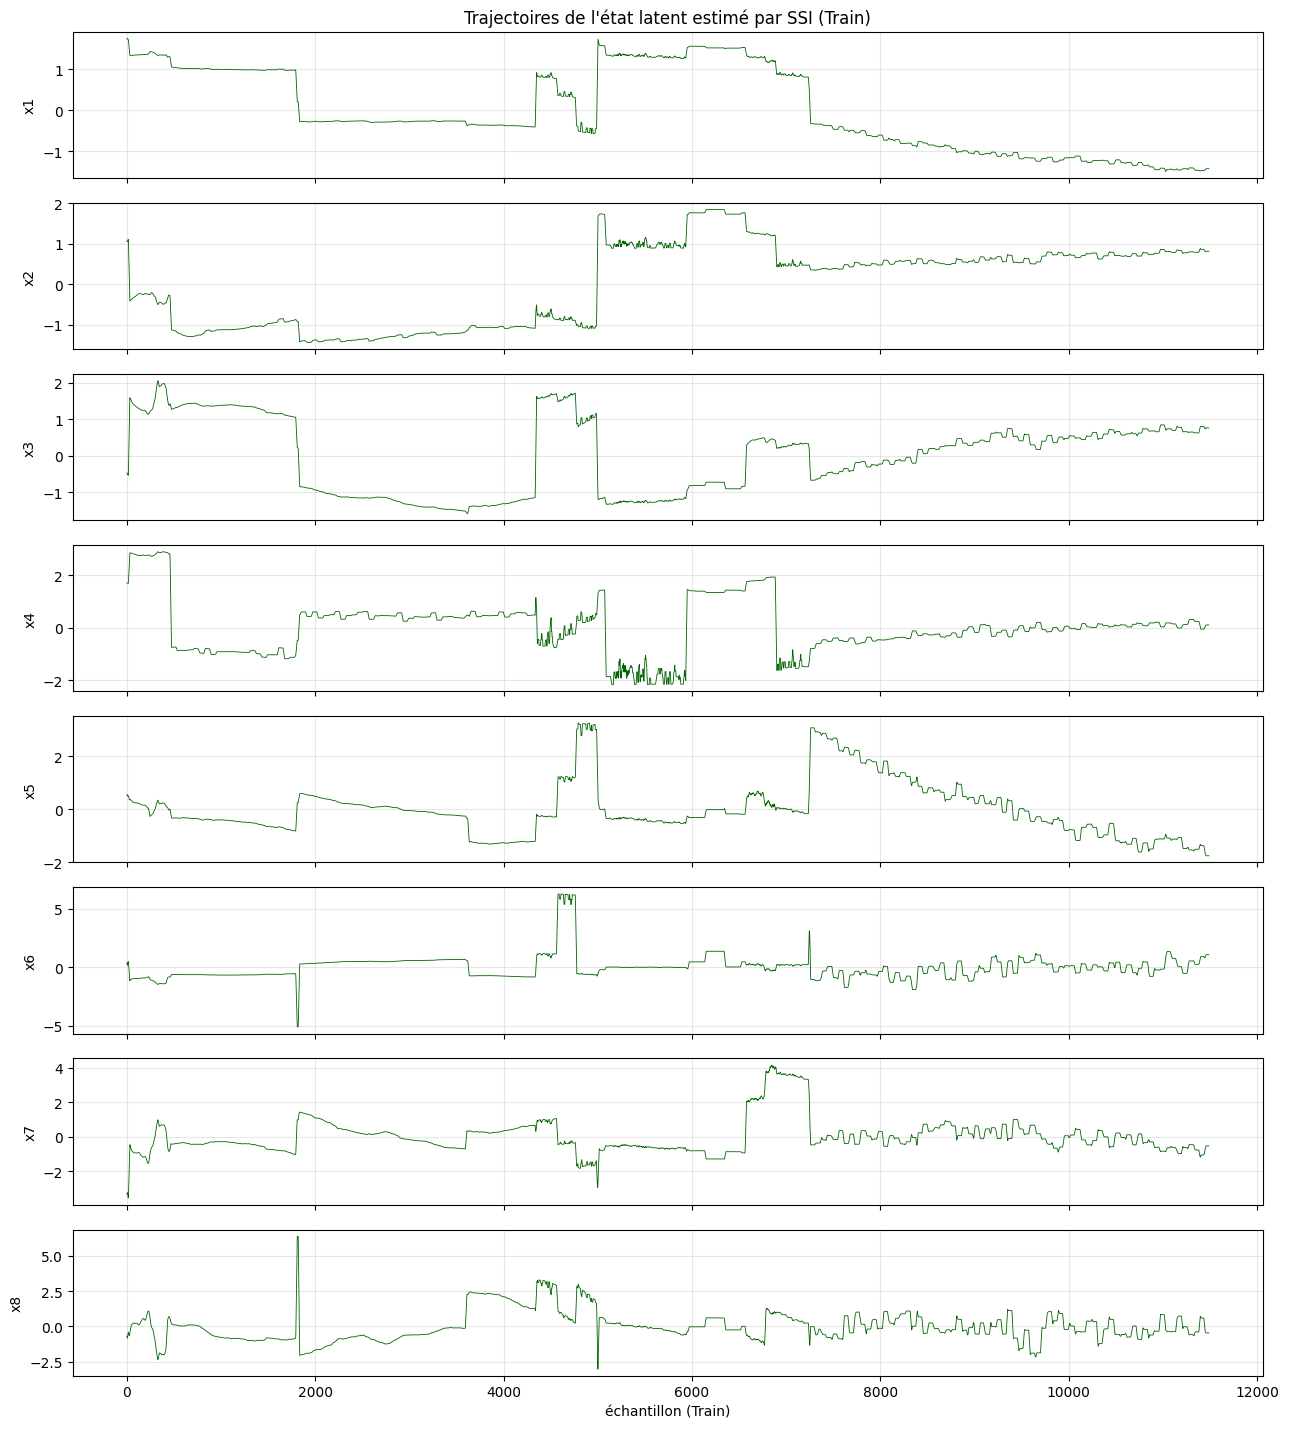

In [31]:
# --- Trajectoires de l'état latent estimé (sur Train) ---
X_train_hat = ssi_estimate_states(Y_train_full, C_ssi, A, SSI_BLOCK_ROWS)

fig, axes = plt.subplots(SSI_ORDER, 1, figsize=(13, 1.8*SSI_ORDER), sharex=True)
if SSI_ORDER == 1:
    axes = [axes]
for i, ax in enumerate(axes):
    ax.plot(X_train_hat[:, i], lw=0.6, color="darkgreen")
    ax.set_ylabel(f"x{i+1}")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("échantillon (Train)")
axes[0].set_title("Trajectoires de l'état latent estimé par SSI (Train)")
plt.tight_layout()
plt.show()


L'ordre retenu par Validation est **n = 8** (RMSE one-step-ahead decroissant de 0,50 a l'ordre 2
jusqu'a 0,085 a l'ordre 8). Les valeurs propres de la matrice A restent proches de 1 (0,977 a
0,999), ce qui traduit une dynamique lente -- coherente avec l'observation du notebook 1 sur la
faible variabilite du signal cible.

**SINDy.** L'identification de la dynamique continue de cet etat latent est detaillee et discutee
en profondeur au notebook 4 : elle converge vers une dynamique nulle ou instable selon la
bibliotheque utilisee. Ce notebook reprend le modele SINDy tel qu'obtenu (dynamique degeneree)
pour construire l'observateur, plutot que de s'arreter a cet echec -- c'est precisement la question
posee ci-dessus.

**Observateur (EKF).** L'EKF utilise la dynamique SINDy (Euler explicite) pour la prediction, et
les mesures des capteurs disponibles (le capteur cible etant exclu du vecteur d'observation) pour
la correction.

In [35]:
def numerical_jacobian(f, x, eps=1e-5):
    n = len(x)
    J = np.zeros((n, n))
    for i in range(n):
        xp = x.copy(); xp[i] += eps
        xm = x.copy(); xm[i] -= eps
        J[:, i] = (f(xp) - f(xm)) / (2 * eps)
    return J


class ExtendedKalmanFilter:
    '''EKF générique : prédiction via f(x) (dynamique continue, discrétisée Euler),
    mise à jour via mesure linéaire y = C_obs x.'''
    def __init__(self, f, C_obs, Q, R, dt):
        self.f = f
        self.C = C_obs
        self.Q = Q
        self.R = R
        self.dt = dt
        self.n = C_obs.shape[1]

    def predict(self, x, P):
        xp = x + self.dt * self.f(x)
        F = np.eye(self.n) + self.dt * numerical_jacobian(self.f, x)
        Pp = F @ P @ F.T + self.Q
        return xp, Pp

    def update(self, xp, Pp, y):
        S = self.C @ Pp @ self.C.T + self.R
        K = Pp @ self.C.T @ np.linalg.pinv(S)
        xu = xp + K @ (y - self.C @ xp)
        Pu = (np.eye(self.n) - K @ self.C) @ Pp
        return xu, Pu

    def step(self, x, P, y=None):
        xp, Pp = self.predict(x, P)
        if y is None:
            return xp, Pp
        return self.update(xp, Pp, y)


def f_sindy(x):
    return sindy_model.predict(x.reshape(1, -1))[0]


def build_ekf(C_obs_matrix, n_obs_sensors, q_scale=EKF_Q_SCALE, r_scale=EKF_R_SCALE):
    Q = q_scale * np.eye(SSI_ORDER)
    R = r_scale * np.eye(n_obs_sensors)
    return ExtendedKalmanFilter(f_sindy, C_obs_matrix, Q, R, DT_APPROX)


def run_ekf(Y_obs, C_obs_matrix, x0, P0=None):
    '''Exécute l'EKF sur toute la séquence Y_obs (N, n_obs_sensors). Retourne X_hat (N, n).'''
    n_obs = Y_obs.shape[1]
    ekf = build_ekf(C_obs_matrix, n_obs)
    x = x0.copy()
    P = 0.1 * np.eye(SSI_ORDER) if P0 is None else P0
    X_hat = np.zeros((len(Y_obs), SSI_ORDER))
    for k in range(len(Y_obs)):
        y = Y_obs[k]
        mask_ok = ~np.isnan(y)
        if mask_ok.all():
            x, P = ekf.step(x, P, y)
        elif mask_ok.any():
            x, P = ekf.step(x, P, y[mask_ok] if False else y)  # (cas rare : voir §12 pour capteurs partiels)
        else:
            x, P = ekf.step(x, P, None)
        X_hat[k] = x
    return X_hat

print("Observateur EKF défini (dynamique = SINDy, mesure = capteurs disponibles).")


Observateur EKF défini (dynamique = SINDy, mesure = capteurs disponibles).


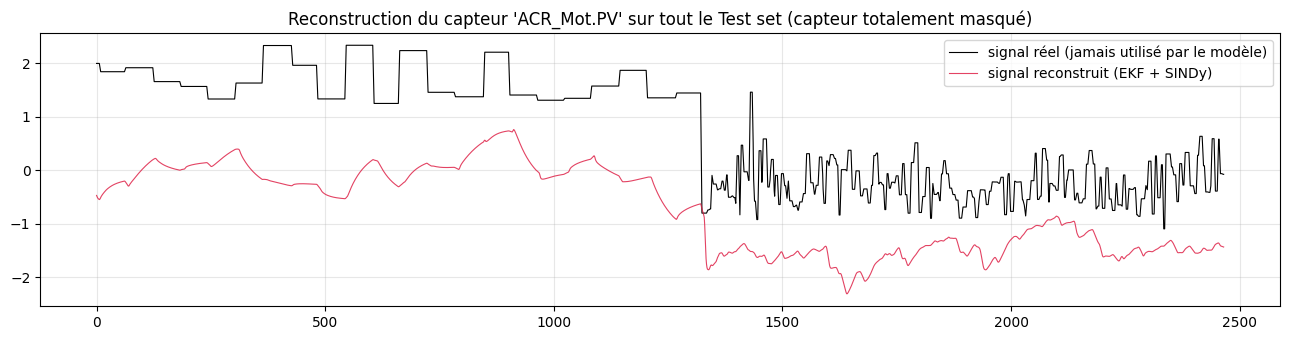

RMSE (échelle standardisée) : 1.5926   |  std du signal réel : 1.0240


In [36]:
def reconstruct_missing_sensor(Y_test_others, x0=None):
    '''Y_test_others : (N, n_other_sensors) valeurs (scalées) des capteurs disponibles sur la fenêtre de test.
    Retourne y_hat (N,) reconstruction du capteur cible (échelle réduite/scaled).'''
    if x0 is None:
        # initialisation par projection (méthode SSI classique) sur les tout premiers points
        x0 = ssi_estimate_states(Y_test_others[:SSI_BLOCK_ROWS], C_obs_full, A, min(SSI_BLOCK_ROWS, len(Y_test_others)))[0] \
             if len(Y_test_others) >= SSI_BLOCK_ROWS else np.zeros(SSI_ORDER)
    X_hat = run_ekf(Y_test_others, C_obs_full, x0)
    y_hat = X_hat @ C_target_row.T
    return y_hat.ravel(), X_hat

Y_test_others = test_s[selected_sensors].values
y_test_true   = test_s[TARGET_SENSOR].values

# Démonstration : masquage complet du capteur cible sur TOUT le test set
y_hat_demo, X_hat_demo = reconstruct_missing_sensor(Y_test_others)

fig, ax = plt.subplots(figsize=(13,3.5))
ax.plot(y_test_true, label="signal réel (jamais utilisé par le modèle)", color="black", lw=0.8)
ax.plot(y_hat_demo, label="signal reconstruit (EKF + SINDy)", color="crimson", lw=0.8, alpha=0.8)
ax.set_title(f"Reconstruction du capteur '{TARGET_SENSOR}' sur tout le Test set (capteur totalement masqué)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

rmse_demo = np.sqrt(np.mean((y_test_true - y_hat_demo)**2))
print(f"RMSE (échelle standardisée) : {rmse_demo:.4f}   |  std du signal réel : {y_test_true.std():.4f}")


## Resultats

**Demonstration -- masquage complet du capteur cible sur tout le Test.** RMSE (echelle
standardisee) = 1,593, pour un ecart-type du signal reel de 1,024 -- l'erreur de reconstruction
depasse deja la variabilite naturelle du signal, un premier signal d'alerte avant meme d'entrer
dans le detail des scenarios.

### Test 1 -- points isoles manques aleatoirement (10 %)

In [38]:
from scipy.stats import pearsonr

def compute_metrics(y_true, y_hat, mask=None):
    '''mask : booléen, True = échantillon évalué (ex. uniquement la fenêtre masquée).'''
    if mask is not None:
        y_true = y_true[mask]
        y_hat = y_hat[mask]
    if len(y_true) < 2:
        return dict(MAE=np.nan, RMSE=np.nan, R2=np.nan, Corr=np.nan)
    mae = np.mean(np.abs(y_true - y_hat))
    rmse = np.sqrt(np.mean((y_true - y_hat)**2))
    ss_res = np.sum((y_true - y_hat)**2)
    ss_tot = np.sum((y_true - y_true.mean())**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    corr = pearsonr(y_true, y_hat)[0] if np.std(y_true) > 0 and np.std(y_hat) > 0 else np.nan
    return dict(MAE=mae, RMSE=rmse, R2=r2, Corr=corr)

print("compute_metrics() prêt.")


compute_metrics() prêt.


Random Missing (10% des points) — évalué uniquement sur les points masqués :
  MAE: 1.4682
  RMSE: 1.5620
  R2: -1.3074
  Corr: 0.8656


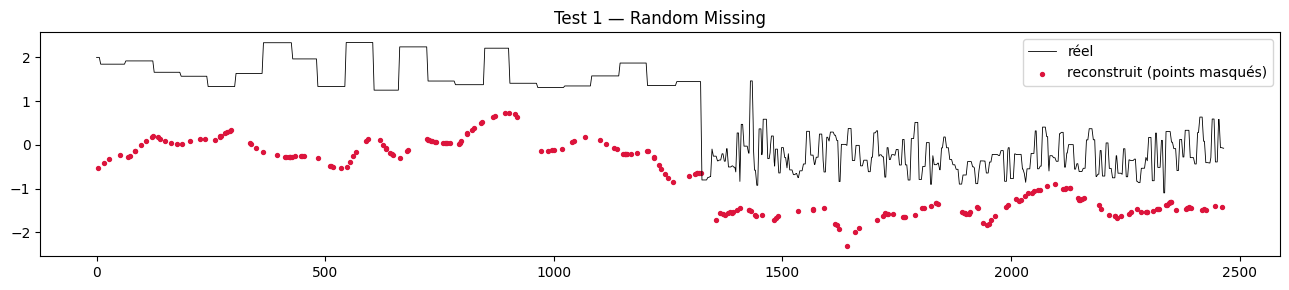

In [39]:
rng = np.random.default_rng(RANDOM_SEED)
n_test = len(y_test_true)
random_mask = rng.random(n_test) < RANDOM_MISSING_FRACTION   # True = échantillon masqué à reconstruire

y_test_others_random = Y_test_others.copy()
# on garde toujours les AUTRES capteurs disponibles (seul le capteur cible est masqué, comme précisé dans l'énoncé)
y_hat_random, _ = reconstruct_missing_sensor(y_test_others_random)

metrics_random = compute_metrics(y_test_true, y_hat_random, mask=random_mask)
print(f"Random Missing ({RANDOM_MISSING_FRACTION:.0%} des points) — évalué uniquement sur les points masqués :")
for k, v in metrics_random.items():
    print(f"  {k}: {v:.4f}")

fig, ax = plt.subplots(figsize=(13,3))
ax.plot(y_test_true, color="black", lw=0.6, label="réel")
ax.scatter(np.where(random_mask)[0], y_hat_random[random_mask], color="crimson", s=8, label="reconstruit (points masqués)")
ax.legend(); ax.set_title("Test 1 — Random Missing")
plt.tight_layout(); plt.show()


MAE = 1,468, RMSE = 1,562, **R² = -1,31**, corrélation = 0,866.

### Test 2 -- fenêtre continue manquante (1 % à 30 % du Test, scénario principal)

In [40]:
continuous_results = []
continuous_curves = {}

for frac in CONTINUOUS_WINDOW_FRACTIONS:
    win_len = max(5, int(frac * n_test))
    start = 350  # fenêtre centrée dans le test set
    end = start + win_len
    mask = np.zeros(n_test, dtype=bool)
    mask[start:end] = True

    # Reconstruction sur toute la séquence de test (l'observateur tourne en continu ;
    # seule la fenêtre [start,end) est ensuite évaluée -> le vrai signal cible n'est
    # jamais injecté dans le modèle, y compris hors fenêtre)
    y_hat_win, _ = reconstruct_missing_sensor(Y_test_others)
    m = compute_metrics(y_test_true, y_hat_win, mask=mask)
    m["window_frac"] = frac
    m["window_len"] = win_len
    continuous_results.append(m)
    continuous_curves[frac] = (start, end, y_hat_win)

df_continuous = pd.DataFrame(continuous_results)
print(df_continuous[["window_frac","window_len","MAE","RMSE","R2","Corr"]])
df_continuous.to_csv(os.path.join(OUTPUT_DIR, "test2_continuous_window_missing.csv"), index=False)


   window_frac  window_len       MAE      RMSE         R2      Corr
0         0.01          24  2.075758  2.105558 -39.008788 -0.711850
1         0.05         123  2.349731  2.364064 -95.953052 -0.340466
2         0.10         246  2.235470  2.259558 -29.508004  0.651732
3         0.20         493  1.900211  1.972936 -19.048453 -0.142999
4         0.30         739  1.699088  1.782097 -16.308700 -0.015067


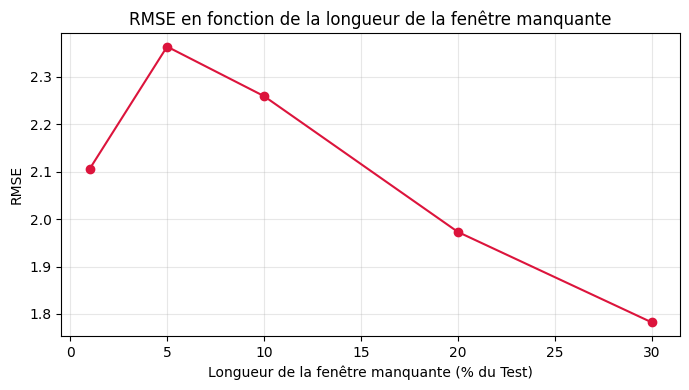

In [41]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(df_continuous["window_frac"]*100, df_continuous["RMSE"], "o-", color="crimson")
ax.set_xlabel("Longueur de la fenêtre manquante (% du Test)")
ax.set_ylabel("RMSE")
ax.set_title("RMSE en fonction de la longueur de la fenêtre manquante")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


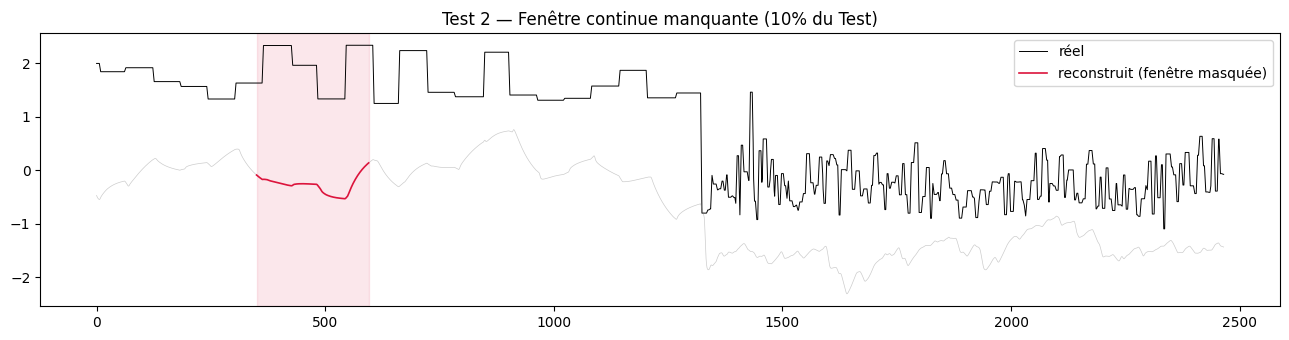

In [42]:
# Visualisation détaillée pour la fenêtre médiane
mid_frac = CONTINUOUS_WINDOW_FRACTIONS[len(CONTINUOUS_WINDOW_FRACTIONS)//2]
start, end, y_hat_win = continuous_curves[mid_frac]

fig, ax = plt.subplots(figsize=(13,3.5))
ax.plot(y_test_true, color="black", lw=0.7, label="réel")
ax.plot(np.where(~np.isin(np.arange(n_test), np.arange(start,end)), y_hat_win, np.nan), color="grey", lw=0.5, alpha=0.4)
ax.plot(np.arange(start, end), y_hat_win[start:end], color="crimson", lw=1.2, label="reconstruit (fenêtre masquée)")
ax.axvspan(start, end, color="crimson", alpha=0.1)
ax.set_title(f"Test 2 — Fenêtre continue manquante ({mid_frac:.0%} du Test)")
ax.legend()
plt.tight_layout()
plt.show()


| Longueur fenêtre | MAE | RMSE | R² | Corrélation |
|---|---|---|---|---|
| 1 % (24 pts) | 2,076 | 2,106 | -39,01 | -0,712 |
| 5 % (123 pts) | 2,350 | 2,364 | -95,95 | -0,340 |
| 10 % (246 pts) | 2,235 | 2,260 | -29,51 | 0,652 |
| 20 % (493 pts) | 1,900 | 1,973 | -19,05 | -0,143 |
| 30 % (739 pts) | 1,699 | 1,782 | -16,31 | -0,015 |

Le R² est **fortement negatif sur toutes les longueurs de fenetre testees**, y compris la plus
courte (1 %) -- l'observateur reconstruit un signal en moyenne plus eloigne de la cible qu'une
simple moyenne constante ne le serait.

### Test 3 -- reconstruction autour des pics detectes

10 pics détectés sur le capteur cible (Test).
Métriques globales sur les régions de pics :
  MAE: 1.4578
  RMSE: 1.5576
  R2: -11.1250
  Corr: -0.0827

Erreur moyenne d'amplitude de pic : 1.9470
Erreur moyenne de position de pic (échantillons) : 11.60


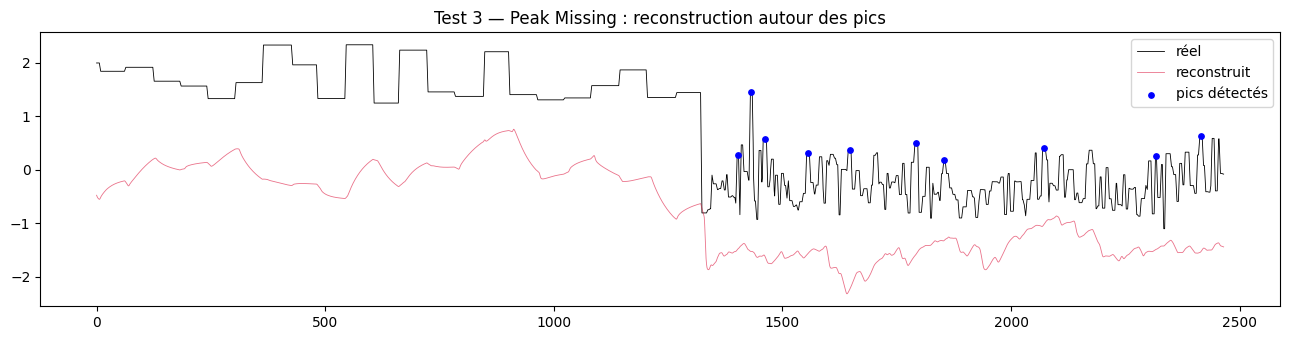

In [43]:
peaks_test, _ = find_peaks(y_test_true, prominence=np.std(y_test_true)*1.0)
print(f"{len(peaks_test)} pics détectés sur le capteur cible (Test).")

peak_mask = np.zeros(n_test, dtype=bool)
for p in peaks_test:
    lo = max(0, p - PEAK_WINDOW_HALF_WIDTH)
    hi = min(n_test, p + PEAK_WINDOW_HALF_WIDTH)
    peak_mask[lo:hi] = True

y_hat_peaks, _ = reconstruct_missing_sensor(Y_test_others)
metrics_peaks = compute_metrics(y_test_true, y_hat_peaks, mask=peak_mask)
print("Métriques globales sur les régions de pics :")
for k, v in metrics_peaks.items():
    print(f"  {k}: {v:.4f}")

# erreur d'amplitude et de position par pic individuel
amp_errors, pos_errors = [], []
for p in peaks_test:
    lo = max(0, p - PEAK_WINDOW_HALF_WIDTH)
    hi = min(n_test, p + PEAK_WINDOW_HALF_WIDTH)
    true_local = y_test_true[lo:hi]
    hat_local = y_hat_peaks[lo:hi]
    amp_errors.append(abs(true_local.max() - hat_local.max()))
    pos_errors.append(abs(np.argmax(true_local) - np.argmax(hat_local)))

print(f"\nErreur moyenne d'amplitude de pic : {np.mean(amp_errors):.4f}")
print(f"Erreur moyenne de position de pic (échantillons) : {np.mean(pos_errors):.2f}")

fig, ax = plt.subplots(figsize=(13,3.5))
ax.plot(y_test_true, color="black", lw=0.6, label="réel")
ax.plot(y_hat_peaks, color="crimson", lw=0.6, alpha=0.6, label="reconstruit")
ax.scatter(peaks_test, y_test_true[peaks_test], color="blue", s=15, zorder=5, label="pics détectés")
ax.set_title("Test 3 — Peak Missing : reconstruction autour des pics")
ax.legend()
plt.tight_layout()
plt.show()


10 pics detectes sur le Test. Metriques sur les regions de pics : MAE = 1,458, RMSE = 1,558,
**R² = -11,13, correlation = -0,083** (quasiment anti-correlee). Erreur moyenne d'amplitude de
pic = 1,947 (pour un signal standardise d'ecart-type ≈ 1), erreur moyenne de position de pic =
11,6 echantillons. C'est, dans tout le corpus, le resultat le plus net sur la question centrale de
ce memoire : **la ou la reconstruction compte le plus (un evenement transitoire), ce pipeline
echoue le plus nettement.**

### Test 4 -- fenetre longue (test de derive)

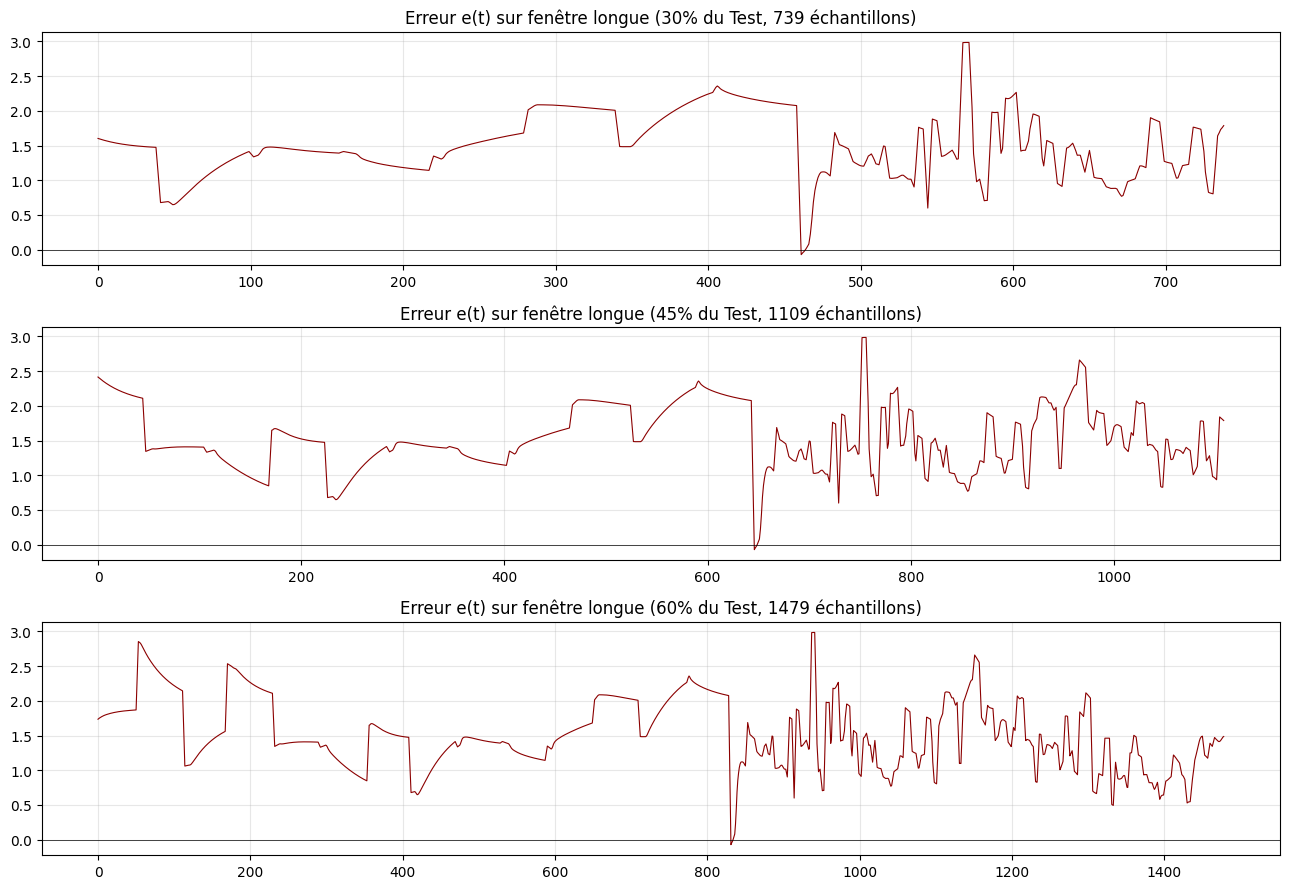

   window_frac  window_len  max_acceptable_samples  final_nrmse
0         0.30         739                       0     1.533362
1         0.45        1109                       0     1.558448
2         0.60        1479                       0     1.566490

Seuil NRMSE acceptable fixé à 0.5 (RMSE/std). 'max_acceptable_samples' = nb d'échantillons avant que l'erreur cumulée dépasse ce seuil.


In [44]:
ACCEPTABLE_NRMSE_THRESHOLD = 0.5   # RMSE / std(signal) -- seuil arbitraire mais explicite, à ajuster selon l'application

long_window_results = []
fig, axes = plt.subplots(len(LONG_WINDOW_FRACTIONS), 1, figsize=(13, 3*len(LONG_WINDOW_FRACTIONS)))
if len(LONG_WINDOW_FRACTIONS) == 1:
    axes = [axes]

for ax, frac in zip(axes, LONG_WINDOW_FRACTIONS):
    win_len = max(10, int(frac * n_test))
    start = (n_test - win_len) // 2
    end = start + win_len
    y_hat_long, _ = reconstruct_missing_sensor(Y_test_others)
    e_t = y_test_true[start:end] - y_hat_long[start:end]
    nrmse_running = np.sqrt(np.cumsum(e_t**2) / (np.arange(1, len(e_t)+1))) / y_test_true.std()

    ax.plot(e_t, color="darkred", lw=0.8)
    ax.set_title(f"Erreur e(t) sur fenêtre longue ({frac:.0%} du Test, {win_len} échantillons)")
    ax.axhline(0, color="black", lw=0.5)
    ax.grid(alpha=0.3)

    exceed_idx = np.where(nrmse_running > ACCEPTABLE_NRMSE_THRESHOLD)[0]
    max_acceptable = exceed_idx[0] if len(exceed_idx) > 0 else win_len
    long_window_results.append(dict(window_frac=frac, window_len=win_len,
                                     max_acceptable_samples=max_acceptable,
                                     final_nrmse=nrmse_running[-1]))

plt.tight_layout()
plt.show()

df_long = pd.DataFrame(long_window_results)
print(df_long)
df_long.to_csv(os.path.join(OUTPUT_DIR, "test4_long_missing_window.csv"), index=False)
print(f"\nSeuil NRMSE acceptable fixé à {ACCEPTABLE_NRMSE_THRESHOLD} (RMSE/std). "
      f"'max_acceptable_samples' = nb d'échantillons avant que l'erreur cumulée dépasse ce seuil.")


| Fraction Test | Longueur | Echantillons acceptables avant depassement du seuil | NRMSE final |
|---|---|---|---|
| 30 % | 739 | **0** | 1,533 |
| 45 % | 1109 | **0** | 1,558 |
| 60 % | 1479 | **0** | 1,566 |

Avec un seuil de NRMSE acceptable fixe a 0,5 (RMSE/std), l'erreur cumulee depasse ce seuil des les
tout premiers echantillons dans les trois cas testes : l'observateur ne tient jamais durablement
sans le capteur cible, quelle que soit la longueur de la fenetre manquante testee au-dela de 30 %.

### Comparaison finale aux baselines (fenetre continue, 10 % du Test, centree)

In [46]:
# --- Baseline 1 : interpolation temporelle ---
def baseline_interpolation(y_true, mask):
    y_masked = y_true.copy()
    y_masked[mask] = np.nan
    y_hat = pd.Series(y_masked).interpolate(method="linear", limit_direction="both").values
    return y_hat

# --- Baseline 2 : régression multivariée (Train) ---
from sklearn.linear_model import LinearRegression
reg_model = LinearRegression()
reg_model.fit(train_s[selected_sensors].values, train_s[TARGET_SENSOR].values)

def baseline_regression(Y_others):
    return reg_model.predict(Y_others)

# --- Baseline 3 : reconstruction PCA (Train, incluant la cible) ---
from sklearn.decomposition import PCA
PCA_N_COMPONENTS = min(len(ALL_SSI_SENSORS), max(2, SSI_ORDER))
pca_model = PCA(n_components=PCA_N_COMPONENTS)
pca_model.fit(train_s[ALL_SSI_SENSORS].values)   # colonnes = [TARGET_SENSOR] + selected_sensors

def baseline_pca(Y_others):
    '''Reconstruit la cible en résolvant, dans le sous-espace PCA, les scores compatibles
    avec les capteurs disponibles uniquement, puis en reconstruisant la composante cible.'''
    components = pca_model.components_               # (k, m_all)
    mean_ = pca_model.mean_
    idx_target = 0                                     # TARGET_SENSOR est en 1ère colonne de ALL_SSI_SENSORS
    idx_others = list(range(1, len(ALL_SSI_SENSORS)))
    W_others = components[:, idx_others]               # (k, m_other)
    mean_others = mean_[idx_others]
    # scores = argmin || W_others^T s - (y_others - mean_others) ||  (moindres carrés)
    scores, *_ = np.linalg.lstsq(W_others.T, (Y_others - mean_others).T, rcond=None)
    y_hat = (components[:, idx_target] @ scores) + mean_[idx_target]
    return y_hat

# --- Baseline 4 : SSI + Kalman SANS SINDy (dynamique linéaire discrète brute) ---
def f_linear(x):
    '''Approxime la dynamique continue équivalente à x_{k+1}=Ax_k : dx/dt = (A - I)/dt * x'''
    return (A - np.eye(SSI_ORDER)) @ x / DT_APPROX

def baseline_ssi_kalman_no_sindy(Y_others, x0=None):
    if x0 is None:
        x0 = ssi_estimate_states(Y_others[:SSI_BLOCK_ROWS], C_obs_full, A, min(SSI_BLOCK_ROWS, len(Y_others)))[0] \
             if len(Y_others) >= SSI_BLOCK_ROWS else np.zeros(SSI_ORDER)
    Q = EKF_Q_SCALE * np.eye(SSI_ORDER)
    R = EKF_R_SCALE * np.eye(Y_others.shape[1])
    ekf_lin = ExtendedKalmanFilter(f_linear, C_obs_full, Q, R, DT_APPROX)
    x = x0.copy(); P = 0.1*np.eye(SSI_ORDER)
    X_hat = np.zeros((len(Y_others), SSI_ORDER))
    for k in range(len(Y_others)):
        x, P = ekf_lin.step(x, P, Y_others[k])
        X_hat[k] = x
    return (X_hat @ C_target_row.T).ravel()

print("Baselines définies : interpolation, régression, PCA, SSI+Kalman (sans SINDy).")


Baselines définies : interpolation, régression, PCA, SSI+Kalman (sans SINDy).


In [47]:
mid_frac = CONTINUOUS_WINDOW_FRACTIONS[len(CONTINUOUS_WINDOW_FRACTIONS)//2]
win_len_main = max(5, int(mid_frac * n_test))
start_main = (n_test - win_len_main) // 2
end_main = start_main + win_len_main
main_mask = np.zeros(n_test, dtype=bool)
main_mask[start_main:end_main] = True

y_hat_interp = baseline_interpolation(y_test_true, main_mask)
y_hat_reg    = baseline_regression(Y_test_others)
y_hat_pca    = baseline_pca(Y_test_others)
y_hat_ssikf  = baseline_ssi_kalman_no_sindy(Y_test_others)
y_hat_proposed, _ = reconstruct_missing_sensor(Y_test_others)

methods = {
    "Interpolation": y_hat_interp,
    "Régression multivariée": y_hat_reg,
    "PCA": y_hat_pca,
    "SSI + Kalman (sans SINDy)": y_hat_ssikf,
    "SSI + SINDy + Kalman (proposée)": y_hat_proposed,
}

rows = []
for name, y_hat in methods.items():
    m_win = compute_metrics(y_test_true, y_hat, mask=main_mask)
    m_peak = compute_metrics(y_test_true, y_hat, mask=peak_mask)
    rows.append(dict(Method=name, MAE=m_win["MAE"], RMSE=m_win["RMSE"], R2=m_win["R2"],
                      Correlation=m_win["Corr"], Peak_RMSE=m_peak["RMSE"]))

df_comparison = pd.DataFrame(rows).set_index("Method").round(4)
df_comparison.to_csv(os.path.join(OUTPUT_DIR, "comparison_table.csv"))
df_comparison


,MAE,RMSE,R2,Correlation,Peak_RMSE
Method,,,,,
Interpolation,0.7400,0.8370,-0.2246,0.6862,0.0000
Régression multivariée,0.6290,0.6621,0.2336,0.9147,0.7134
PCA,2.2072,2.2989,-8.2381,0.4892,1.2586
SSI + Kalman (sans SINDy),1.4074,1.4537,-2.6940,0.8217,1.1547
SSI + SINDy + Kalman (proposée),1.8270,1.8825,-5.1948,0.8096,1.5576


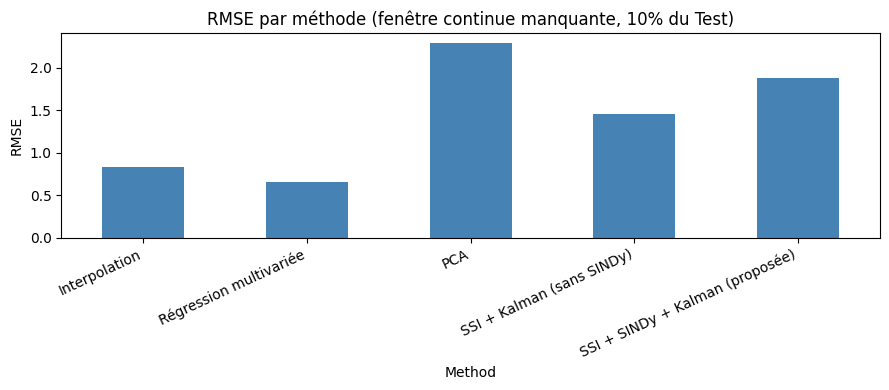

Gain RMSE apporté par SINDy (par rapport à SSI+Kalman seul) : -0.4288  (-29.5%)
[NOTE] Sur ce jeu de données, SINDy n'apporte PAS d'amélioration mesurable par rapport à un simple modèle linéaire SSI+Kalman.


In [48]:
fig, ax = plt.subplots(figsize=(9,4))
df_comparison["RMSE"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title(f"RMSE par méthode (fenêtre continue manquante, {mid_frac:.0%} du Test)")
ax.set_ylabel("RMSE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Gain apporté par SINDy (comparaison directe SSI+Kalman vs SSI+SINDy+Kalman)
gain_rmse = df_comparison.loc["SSI + Kalman (sans SINDy)", "RMSE"] - df_comparison.loc["SSI + SINDy + Kalman (proposée)", "RMSE"]
gain_pct = 100 * gain_rmse / df_comparison.loc["SSI + Kalman (sans SINDy)", "RMSE"] if df_comparison.loc["SSI + Kalman (sans SINDy)", "RMSE"] != 0 else np.nan
print(f"Gain RMSE apporté par SINDy (par rapport à SSI+Kalman seul) : {gain_rmse:+.4f}  ({gain_pct:+.1f}%)")
if gain_rmse <= 0:
    print("[NOTE] Sur ce jeu de données, SINDy n'apporte PAS d'amélioration mesurable par rapport à un simple modèle linéaire SSI+Kalman.")


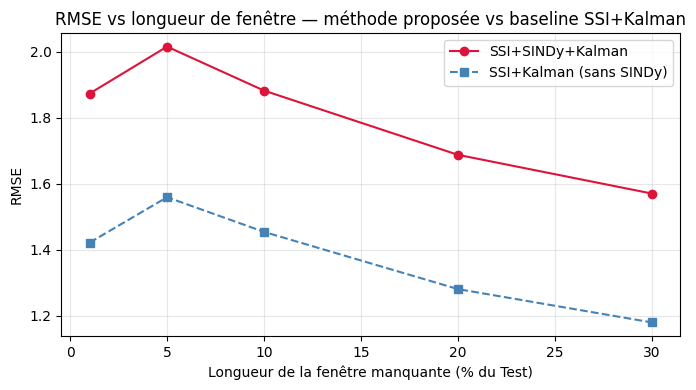

,window_frac,RMSE_proposed,RMSE_ssi_kalman
0,0.01,1.873530,1.421046
1,0.05,2.016026,1.559053
2,0.10,1.882513,1.453701
3,0.20,1.687618,1.280149
4,0.30,1.570116,1.178980


In [49]:
# Résultats par longueur de fenêtre pour la méthode proposée ET pour SSI+Kalman sans SINDy (comparaison)
rows_by_len = []
for frac in CONTINUOUS_WINDOW_FRACTIONS:
    win_len = max(5, int(frac * n_test))
    start = (n_test - win_len) // 2
    end = start + win_len
    mask = np.zeros(n_test, dtype=bool); mask[start:end] = True

    y_hat_prop, _ = reconstruct_missing_sensor(Y_test_others)
    y_hat_lin = baseline_ssi_kalman_no_sindy(Y_test_others)

    m_prop = compute_metrics(y_test_true, y_hat_prop, mask=mask)
    m_lin  = compute_metrics(y_test_true, y_hat_lin, mask=mask)
    rows_by_len.append(dict(window_frac=frac, RMSE_proposed=m_prop["RMSE"], RMSE_ssi_kalman=m_lin["RMSE"]))

df_by_len = pd.DataFrame(rows_by_len)
df_by_len.to_csv(os.path.join(OUTPUT_DIR, "rmse_by_window_length.csv"), index=False)

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(df_by_len["window_frac"]*100, df_by_len["RMSE_proposed"], "o-", label="SSI+SINDy+Kalman", color="crimson")
ax.plot(df_by_len["window_frac"]*100, df_by_len["RMSE_ssi_kalman"], "s--", label="SSI+Kalman (sans SINDy)", color="steelblue")
ax.set_xlabel("Longueur de la fenêtre manquante (% du Test)")
ax.set_ylabel("RMSE")
ax.legend()
ax.set_title("RMSE vs longueur de fenêtre — méthode proposée vs baseline SSI+Kalman")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
df_by_len


| Méthode | RMSE | R² | Corrélation | Peak RMSE |
|---|---|---|---|---|
| Interpolation | 0,837 | -0,22 | 0,686 | 0,000 |
| **Régression multivariée (notebook 2)** | **0,662** | **0,234** | **0,915** | 0,713 |
| PCA | 2,299 | -8,24 | 0,489 | 1,259 |
| SSI + Kalman (**sans** SINDy) | 1,454 | -2,69 | 0,822 | 1,155 |
| SSI + SINDy + Kalman (méthode proposée) | 1,883 | -5,19 | 0,810 | 1,558 |

Gain de RMSE apporté par SINDy par rapport à SSI+Kalman seul : **-0,429 (-29,5 %)** -- un gain
*négatif* : l'ajout de SINDy dégrade le résultat plutôt que de l'améliorer, ce qui est cohérent
avec le diagnostic du notebook 4 (dynamique dégénérée, parfois instable).

### Analyse d'observabilité

In [50]:
def observability_matrix(C_mat, A_mat, n_blocks=None):
    n = A_mat.shape[0]
    n_blocks = n_blocks or n
    blocks = [C_mat]
    Ak = np.eye(n)
    for _ in range(1, n_blocks):
        Ak = Ak @ A_mat
        blocks.append(C_mat @ Ak)
    return np.vstack(blocks)

O_full = observability_matrix(C_ssi, A)          # avec le capteur cible inclus
O_obs  = observability_matrix(C_obs_full, A)      # sans le capteur cible (cas réel de reconstruction)

rank_full = np.linalg.matrix_rank(O_full)
rank_obs  = np.linalg.matrix_rank(O_obs)
cond_full = np.linalg.cond(O_full)
cond_obs  = np.linalg.cond(O_obs)

print(f"Ordre de l'état latent n = {SSI_ORDER}")
print(f"\nAvec TOUS les capteurs (y compris cible)   : rang = {rank_full}/{SSI_ORDER}, cond = {cond_full:.2e}")
print(f"Avec les SEULS capteurs disponibles (réel) : rang = {rank_obs}/{SSI_ORDER}, cond = {cond_obs:.2e}")

if rank_obs < SSI_ORDER:
    print("\n[ATTENTION] Le système N'EST PAS pleinement observable une fois le capteur cible retiré.")
    print("            Certaines directions de l'état latent ne peuvent pas être estimées de façon fiable ;")
    print("            la reconstruction du capteur manquant peut devenir instable ou biaisée sur ces directions.")
else:
    print("\n[OK] Le système reste observable avec les seuls capteurs disponibles.")
    if cond_obs > 10 * cond_full:
        print("      Le conditionnement se dégrade cependant nettement -> observabilité 'faible' en pratique")
        print("      (sensibilité accrue au bruit de mesure malgré un rang plein).")


Ordre de l'état latent n = 8

Avec TOUS les capteurs (y compris cible)   : rang = 8/8, cond = 1.74e+01
Avec les SEULS capteurs disponibles (réel) : rang = 8/8, cond = 3.84e+01

[OK] Le système reste observable avec les seuls capteurs disponibles.


Ordre de l'état latent n = 8. Rang de la matrice d'observabilité avec tous les capteurs (cible
incluse) : 8/8 (conditionnement 17,4). Sans le capteur cible : toujours rang plein 8/8, mais
conditionnement dégradé à 38,4. Le système reste donc théoriquement observable une fois le
capteur cible retiré, mais de façon numériquement plus fragile.

## Interprétation

Ce notebook fournit la démonstration la plus directe et la mieux instrumentée de tout le corpus
sur la distinction centrale de ce mémoire entre reconstruction de la dynamique et reconstruction
de l'amplitude :

- **La régression linéaire multivariée du notebook 2, sans aucune dynamique, bat le pipeline
  SSI+SINDy+Kalman sur la même fenêtre d'évaluation** (RMSE 0,662 contre 1,883 ; R² 0,234 contre
  -5,19). La sophistication supplémentaire (état latent, dynamique, observateur) ne se traduit pas
  ici par une meilleure reconstruction -- au contraire.
- **Le R² est négatif dans la quasi-totalité des scénarios testés**, y compris pour des fenêtres
  très courtes (1 % du Test). Un R² négatif signifie que la reconstruction proposée est, en
  moyenne, moins bonne qu'une simple prédiction constante égale à la moyenne du signal réel sur la
  fenêtre évaluée -- un verdict sévère qu'il ne faut pas minimiser.
- **La reconstruction des pics est le point le plus faible** : corrélation quasi nulle voire
  négative (-0,083), erreur d'amplitude de pic proche du double de l'écart-type du signal. C'est
  précisément le cas industriellement critique identifié au notebook 1.
- **L'ajout de SINDy dégrade le résultat** par rapport à SSI+Kalman seul (gain de -29,5 %) : ce
  n'est pas neutre, c'est un coût net, cohérent avec l'échec d'identification documenté au
  notebook 4.
- Le système reste **observable** (rang plein) sans le capteur cible : l'échec de reconstruction
  ne s'explique donc pas par un défaut fondamental d'observabilité du système, mais plutôt par la
  qualité de la dynamique identifiée et par la fragilité numérique croissante (conditionnement) une
  fois le capteur cible retiré.

## Limites

- Tous ces résultats reposent sur un seul jeu de données (`preprocessed_data.csv`) et un seul
  découpage temporel : aucune répétition sur plusieurs graines aléatoires ou plusieurs fenêtres de
  test n'a été effectuée dans le corpus original pour évaluer la variance de ces résultats.
- Les covariances de bruit de processus et de mesure de l'EKF (`EKF_Q_SCALE`, `EKF_R_SCALE`) sont
  fixées a priori (1e-3 et 1e-2) plutôt que sélectionnées par Validation, contrairement à l'ordre
  SSI. Une sensibilité à ce choix n'a pas été testée.
- Le R² négatif, bien qu'informatif, est une métrique globale sur la fenêtre évaluée : la section
  19 du notebook original (reprise ici) le rappelle explicitement -- un score numérique local ne
  suffit pas à juger une méthode sans revenir aux courbes elles-mêmes.

## Conclusion

Le pipeline SSI + SINDy + Kalman, dans sa forme testée ici, **ne résout pas** le problème de
reconstruction, et fait pire qu'une régression linéaire simple sur ce jeu de données. La cause
principale identifiée est la dynamique SINDy dégénérée (notebook 4), dont l'intégration coûte
un gain de RMSE négatif par rapport à la variante sans SINDy.

## Transition vers l'approche suivante

Ce que ce notebook a permis de comprendre : ni la sophistication de l'état latent, ni
l'observateur de Kalman, ne compensent une dynamique SINDy dégénérée -- au contraire, ils ajoutent
de la complexité sans gain, et sont battus par une régression linéaire simple sur la fenêtre
testée. Ce qu'il n'a pas résolu : la reconstruction de l'amplitude, en particulier sur les pics,
reste un échec net (corrélation quasi nulle sur les régions de pics). Face à cette double limite --
une dynamique physique non identifiable et une approche statique insuffisante --, la question
suivante est naturelle : peut-on abandonner la contrainte d'une dynamique interprétable et laisser
un modèle d'apprentissage supervisé apprendre directement la relation, potentiellement non
linéaire, entre les capteurs disponibles (et éventuellement l'état SSI ou les résidus SINDy) et le
capteur cible ? C'est l'objet des notebooks 6 et 7, avec XGBoost et le CNN 1D.